# Part 3, step 1b – follow-up on the sample comparison
Applies the takeaways from step 1 (`03_part3_step1.ipynb`):

1. **Each cohort separately** – the experiment (batch) effect is the largest signal.
2. **SRR21355389** (blood-contaminated, aging 21mo): aging analysis without it, checked with it.
3. **SRR23914572** (AL 572): the outlier of the intervention samples.
4. **Subtle treatment effects** – how much more similar are mice of the same group than of different groups?
5. **PCA on the most variable genes** instead of all ~27,000 expressed genes (with `scale. = TRUE`, every noisy low-expression gene counts as much as a strong one). Compared here: log TPM (tutorial) and DESeq2's VST values (variance-stabilised counts; top 500 unscaled = the default of DESeq2's `plotPCA`).

Run each cell with **Shift+Enter**.

## Setup

In [1]:
library(tidyverse)
library(DESeq2)   # only for vst()

options(repr.plot.width = 8, repr.plot.height = 5.5)   # plot size in the notebook
# White plot background (otherwise VS Code dark theme shows through)
setHook("before.plot.new", function() par(bg = "white"))
theme_update(plot.background = element_rect(fill = "white", colour = NA))

base <- "~/Documents/claude/Claude/Systems Genomics/RNAseq_aging/for_teammates"
expr <- as.matrix(read.csv(file.path(base, "rsem_tpm.csv.gz"), row.names = 1, check.names = FALSE))
meta <- read.csv(file.path(base, "samples.csv"))
rownames(meta) <- meta$SRR
expr <- expr[, meta$SRR]
counts <- as.matrix(read.csv(file.path(base, "rsem_expected_counts.csv.gz"), row.names = 1, check.names = FALSE))
counts <- counts[, meta$SRR]

outlier_blood <- "SRR21355389"   # aging 21mo
outlier_AL    <- "SRR23914572"   # AL 572
n_top <- 2000                    # number of most variable genes for the PCA

table(meta$cohort)


                 Aging   Dietary Intervention Young Plasma Injection 
                    12                      9                      6 

In [2]:
# Helper functions used for every cohort

# Expressed = detected in at least half the samples OR mean TPM >= 1 (as in the tutorial)
expressed_genes <- function(e) rowMeans(e > 0) >= 0.5 | rowMeans(e) >= 1

# PCA; values = "logTPM" (tutorial: log TPM of expressed genes, scaled per gene)
#   or "vst" (DESeq2 variance-stabilised counts, genes with >= 10 reads in >= 3 samples)
# n_top = NULL uses all genes, otherwise the n_top most variable ones
run_pca <- function(samples, n_top = NULL, values = "logTPM", scale = TRUE) {
  if (values == "logTPM") {
    e <- log1p(expr[, samples])
    e <- e[expressed_genes(expr[, samples]), ]
  } else {
    dds <- DESeqDataSetFromMatrix(round(counts[, samples]), meta[samples, ], design = ~ 1)
    dds <- dds[rowSums(counts(dds) >= 10) >= 3, ]
    e <- assay(vst(dds, blind = TRUE))
  }
  if (!is.null(n_top))
    e <- e[order(apply(e, 1, var), decreasing = TRUE)[1:n_top], ]
  pca <- prcomp(t(e), center = TRUE, scale. = scale)
  list(x = data.frame(pca$x, meta[samples, ]),
       pv = round(100 * pca$sdev^2 / sum(pca$sdev^2), 1),
       n_genes = nrow(e))
}

# PC1 vs PC2 for several PCA versions in one figure; outliers labelled (last 3 digits of SRR id)
plot_pca_grid <- function(pcas, colour, shape = NULL, title = "", ncol = 2,
                          highlight = c(outlier_blood, outlier_AL)) {
  d <- bind_rows(lapply(names(pcas), function(n) {
    p <- pcas[[n]]
    p$x %>% mutate(version = paste0(n, "\nPC1 ", p$pv[1], "%, PC2 ", p$pv[2], "%"))
  }))
  d$version <- factor(d$version, levels = unique(d$version))
  g <- ggplot(d, aes(PC1, PC2, colour = .data[[colour]])) +
    geom_point(size = 3) +
    geom_text(data = subset(d, SRR %in% highlight), aes(label = substr(SRR, 9, 11)),
              colour = "black", size = 3, vjust = -1.1, show.legend = FALSE) +
    facet_wrap(~ version, scales = "free", ncol = ncol) +
    labs(title = title) +
    theme_bw()
  if (!is.null(shape)) g <- g + aes(shape = .data[[shape]])
  g
}

# Short sample labels: group (sex) + last 3 digits of the SRR id
short_label <- function(samples, sex = FALSE) {
  m <- meta[samples, ]
  lab <- sub("aging ", "", m$group)
  if (sex) lab <- paste(lab, toupper(substr(m$sex, 1, 1)))
  paste(lab, substr(m$SRR, 9, 11))
}

# Pearson (log TPM) and Spearman trees side by side
plot_trees <- function(samples, title, sex = FALSE) {
  e <- expr[, samples]
  e <- e[expressed_genes(e), ]
  lab <- short_label(samples, sex)
  layout(matrix(1:2, nrow = 1))
  plot(hclust(as.dist(1 - cor(log1p(e)))), labels = lab,
       main = paste(title, "– Pearson (log TPM)"), xlab = "", sub = "")
  plot(hclust(as.dist(1 - cor(e, method = "spearman"))), labels = lab,
       main = paste(title, "– Spearman"), xlab = "", sub = "")
}

## 1 + 2. Aging cohort, with and without SRR21355389
### Trees

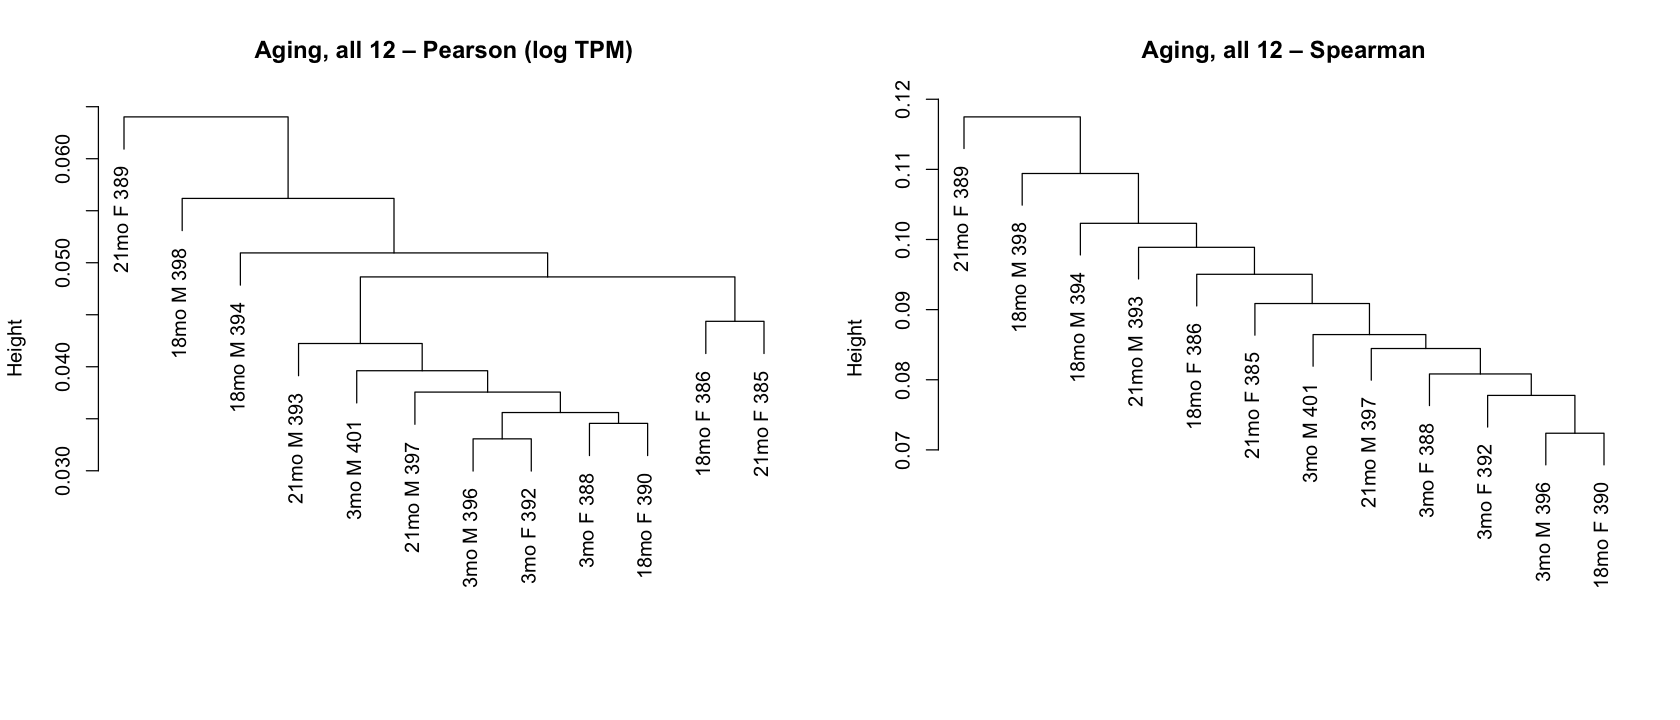

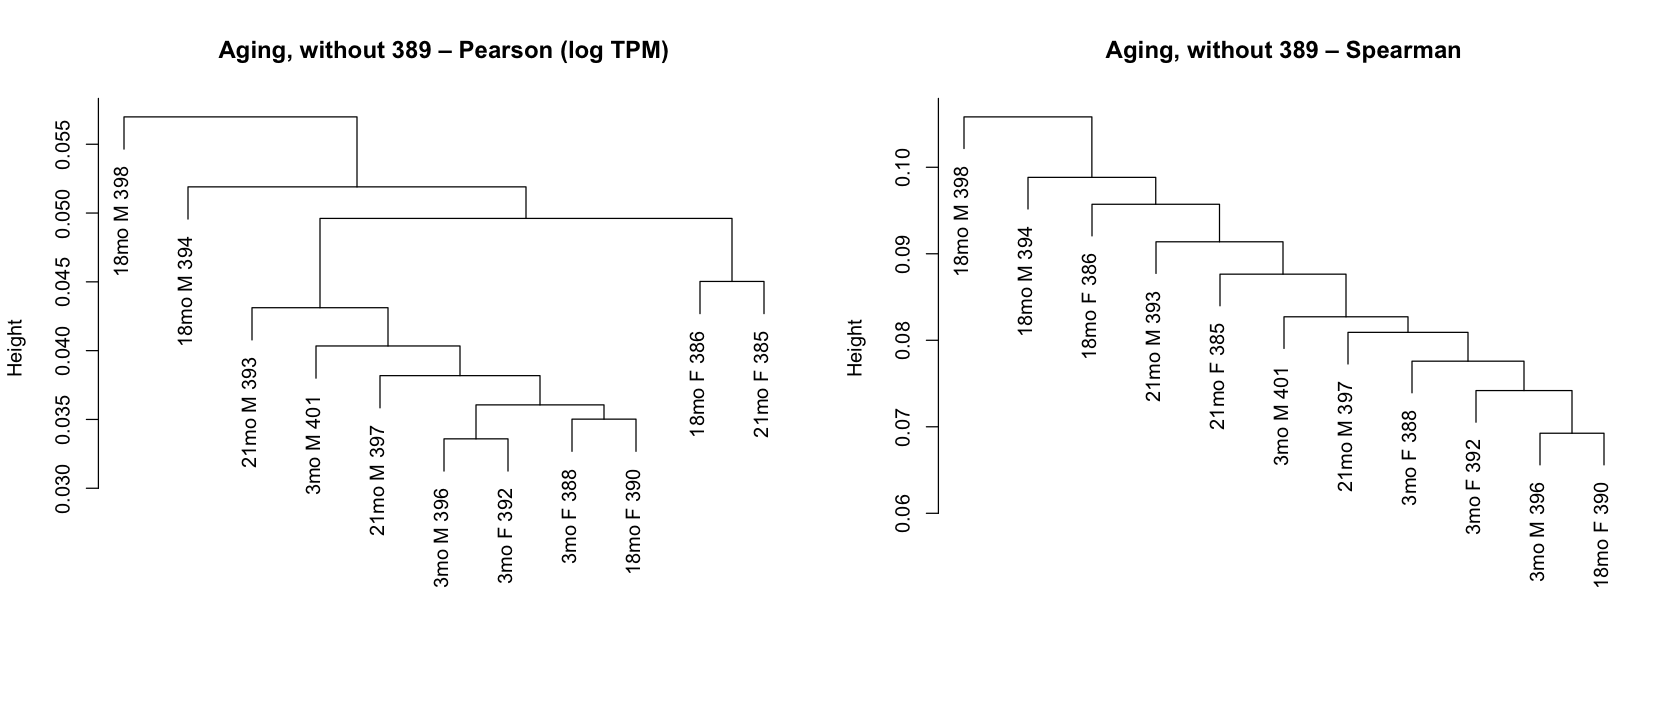

In [3]:
aging_all   <- meta$SRR[meta$cohort == "Aging"]
aging_clean <- setdiff(aging_all, outlier_blood)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_trees(aging_all, "Aging, all 12", sex = TRUE)
plot_trees(aging_clean, "Aging, without 389", sex = TRUE)

### PCA: all expressed genes vs the 2,000 most variable genes (point 5)

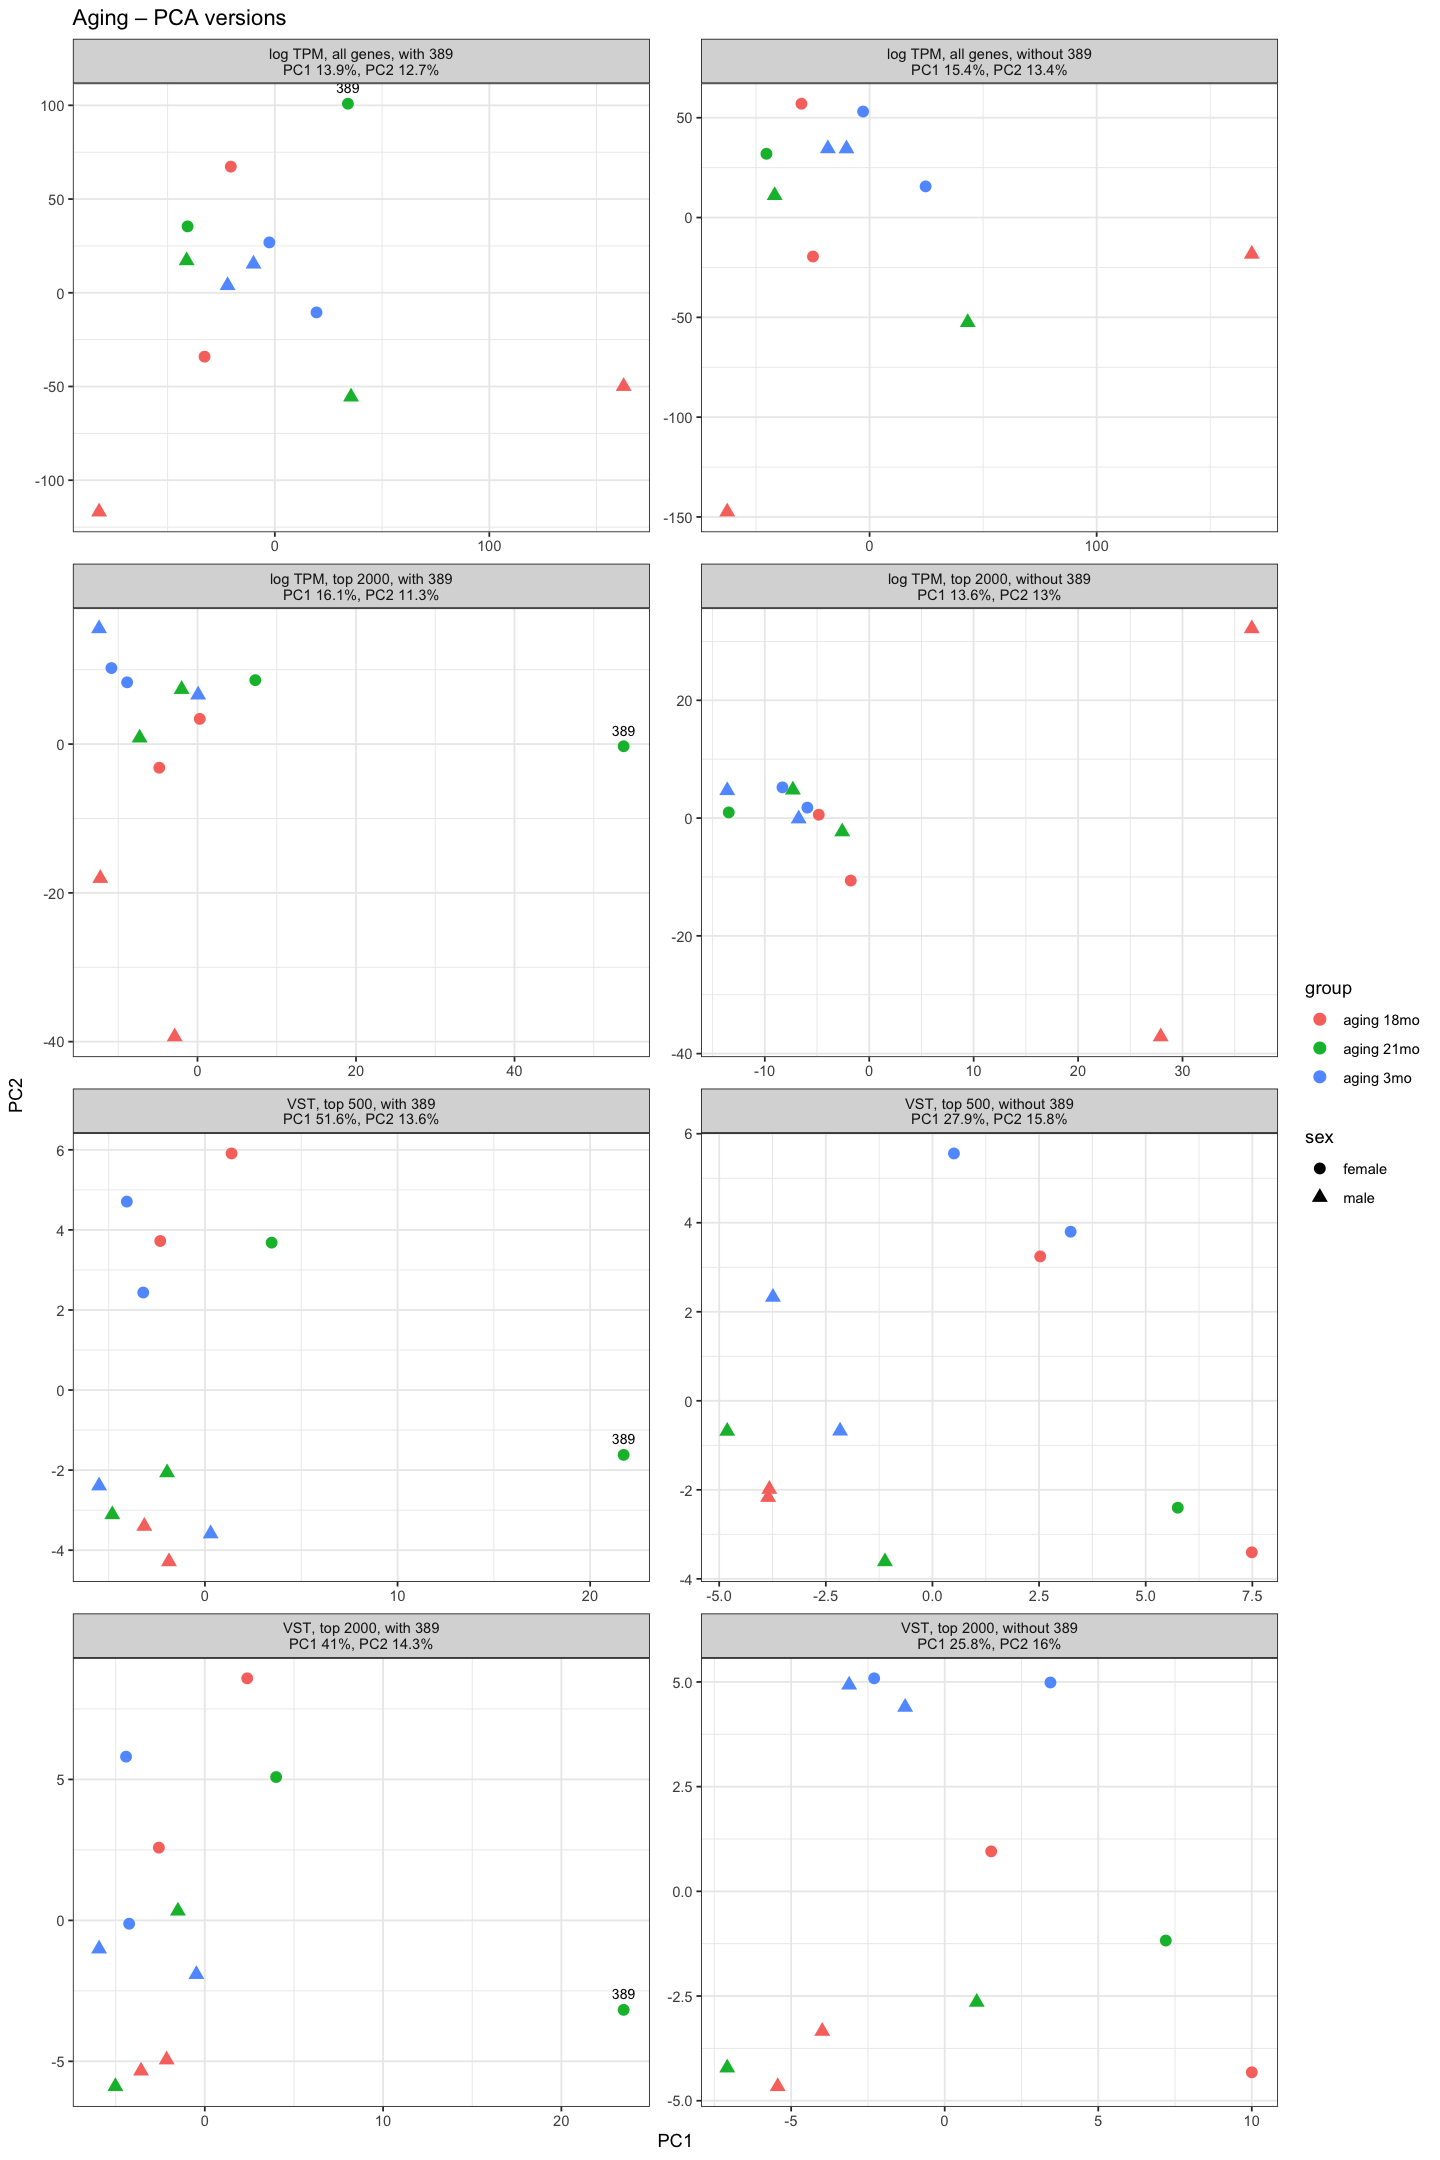

In [4]:
pca_aging <- list(
  "log TPM, all genes, with 389"     = run_pca(aging_all),
  "log TPM, all genes, without 389"  = run_pca(aging_clean),
  "log TPM, top 2000, with 389"      = run_pca(aging_all,   n_top),
  "log TPM, top 2000, without 389"   = run_pca(aging_clean, n_top),
  "VST, top 500, with 389"           = run_pca(aging_all,   500,   values = "vst", scale = FALSE),
  "VST, top 500, without 389"        = run_pca(aging_clean, 500,   values = "vst", scale = FALSE),
  "VST, top 2000, with 389"          = run_pca(aging_all,   n_top, values = "vst", scale = FALSE),
  "VST, top 2000, without 389"       = run_pca(aging_clean, n_top, values = "vst", scale = FALSE)
)

options(repr.plot.width = 12, repr.plot.height = 18)
plot_pca_grid(pca_aging, colour = "group", shape = "sex", title = "Aging – PCA versions")

In [5]:
# Which PC follows age? Spearman correlation of PC1-PC3 with age in months
age_cor <- t(sapply(pca_aging, function(p)
  sapply(paste0("PC", 1:3), function(pc) cor(p$x[[pc]], p$x$age_months, method = "spearman"))))
round(age_cor, 2)

,PC1,PC2,PC3
"log TPM, all genes, with 389",-0.09,0.15,-0.33
"log TPM, all genes, without 389",-0.33,-0.48,-0.32
"log TPM, top 2000, with 389",0.56,-0.35,-0.41
"log TPM, top 2000, without 389",0.21,-0.19,0.61
"VST, top 500, with 389",0.44,0.00,-0.68
"VST, top 500, without 389",-0.07,-0.73,-0.39
"VST, top 2000, with 389",0.47,-0.18,-0.56
"VST, top 2000, without 389",0.00,-0.67,0.30


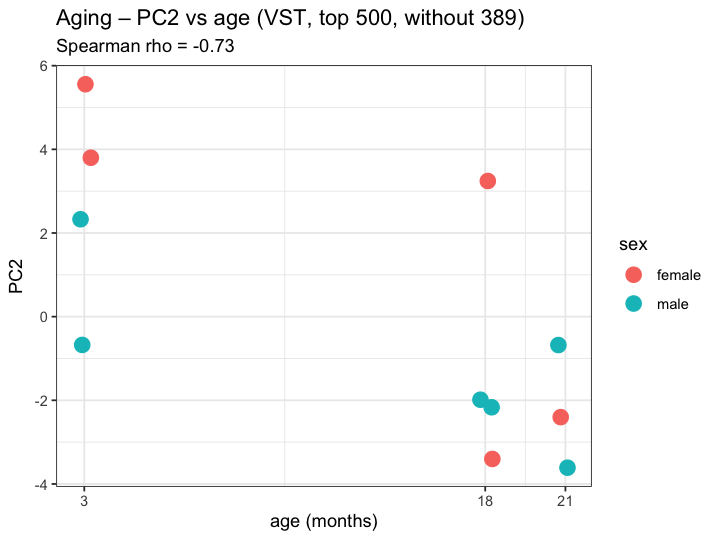

In [6]:
# The version and PC that follow age best (without 389), against age
clean <- grep("without 389", rownames(age_cor), value = TRUE)
best  <- which(abs(age_cor[clean, ]) == max(abs(age_cor[clean, ])), arr.ind = TRUE)
v  <- clean[best[1, 1]]
pc <- colnames(age_cor)[best[1, 2]]
p  <- pca_aging[[v]]

options(repr.plot.width = 6, repr.plot.height = 4.5)
ggplot(p$x, aes(age_months, .data[[pc]], colour = sex)) +
  geom_point(size = 4, position = position_jitter(width = 0.3, seed = 1)) +
  scale_x_continuous(breaks = c(3, 18, 21)) +
  labs(x = "age (months)", title = paste0("Aging – ", pc, " vs age (", v, ")"),
       subtitle = paste0("Spearman rho = ", round(age_cor[v, pc], 2))) +
  theme_bw()

## 1 + 3. Dietary Intervention (AL vs aDR), with and without AL 572

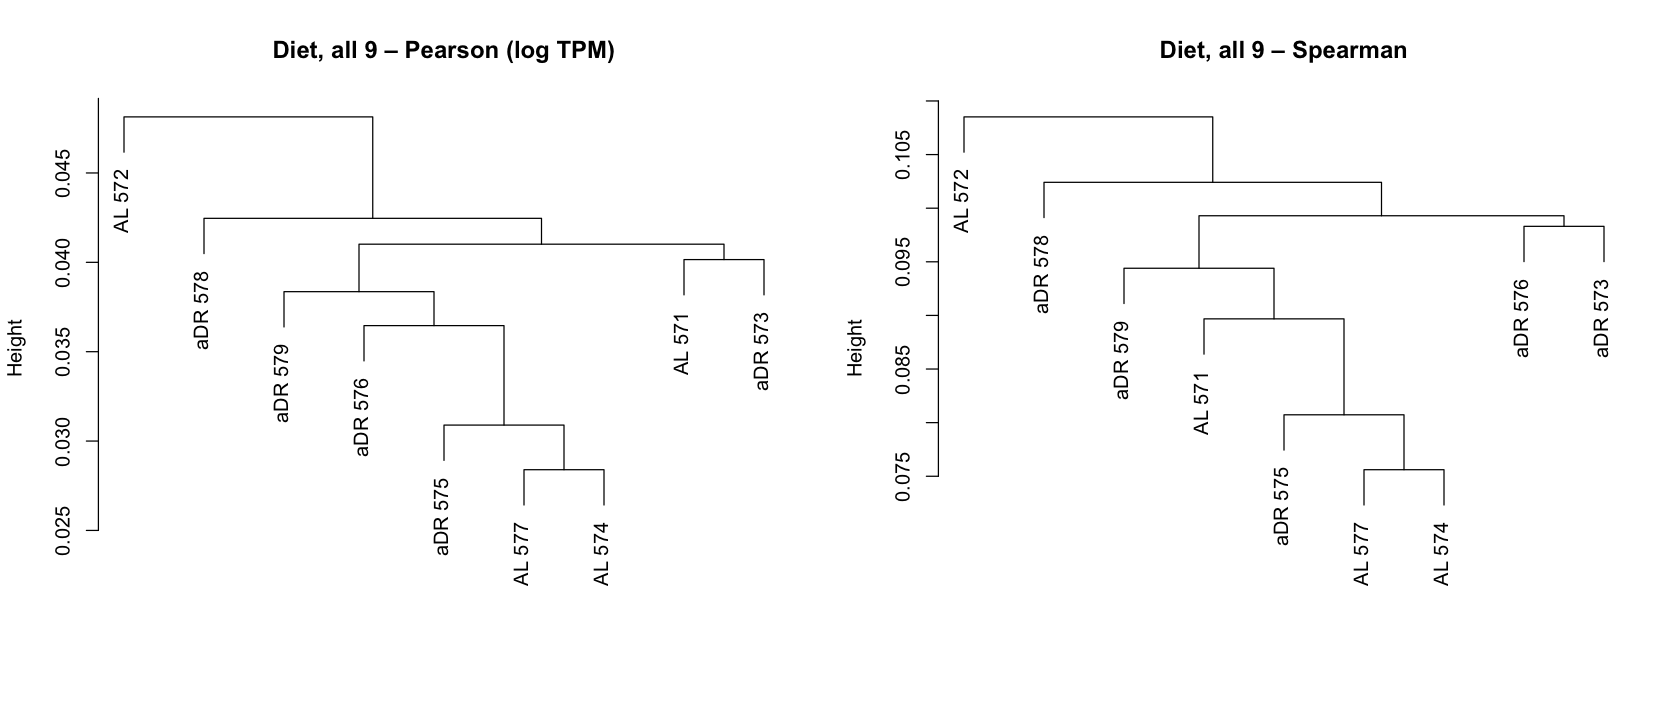

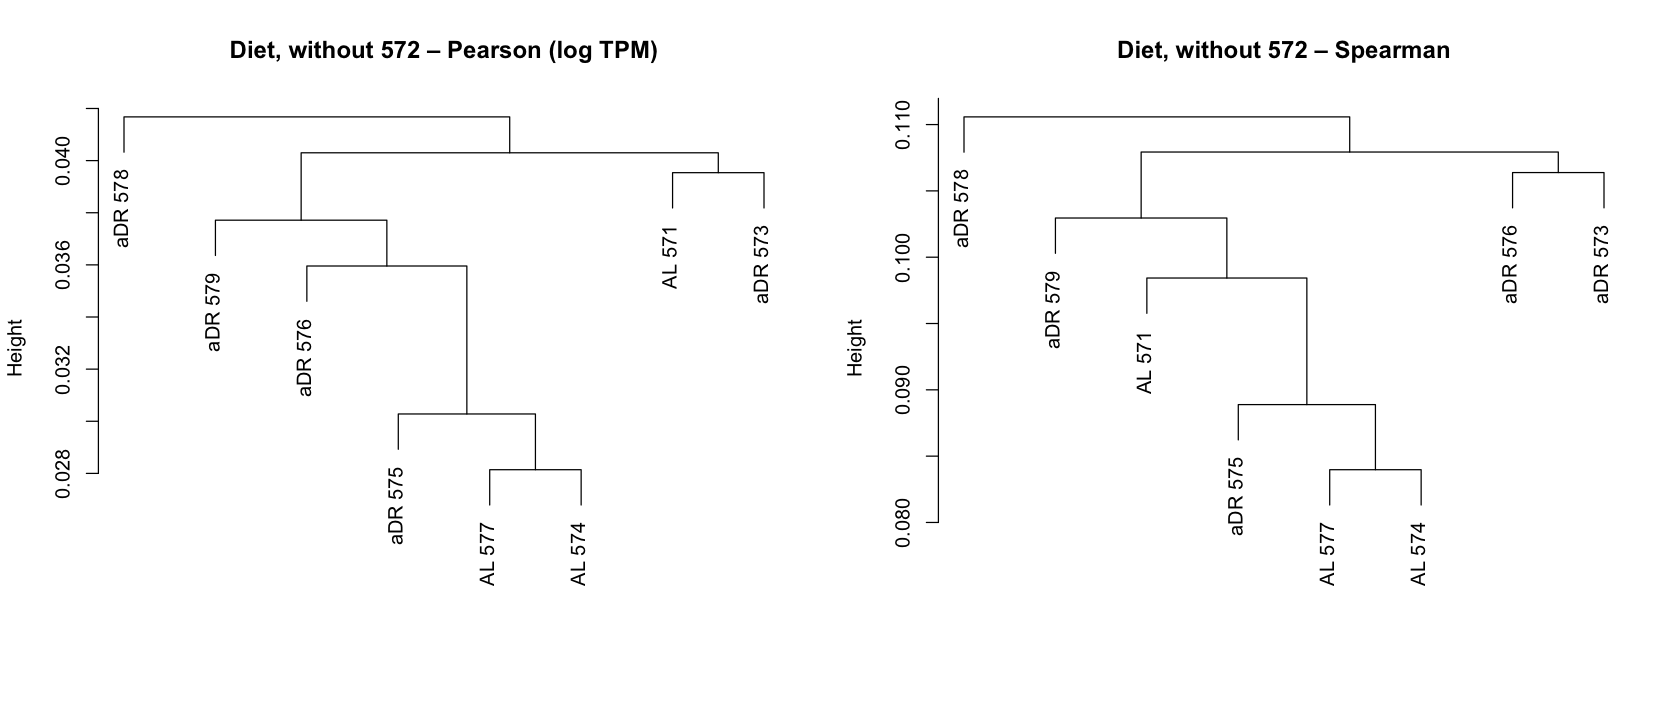

In [7]:
diet_all   <- meta$SRR[meta$cohort == "Dietary Intervention"]
diet_clean <- setdiff(diet_all, outlier_AL)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_trees(diet_all, "Diet, all 9")
plot_trees(diet_clean, "Diet, without 572")

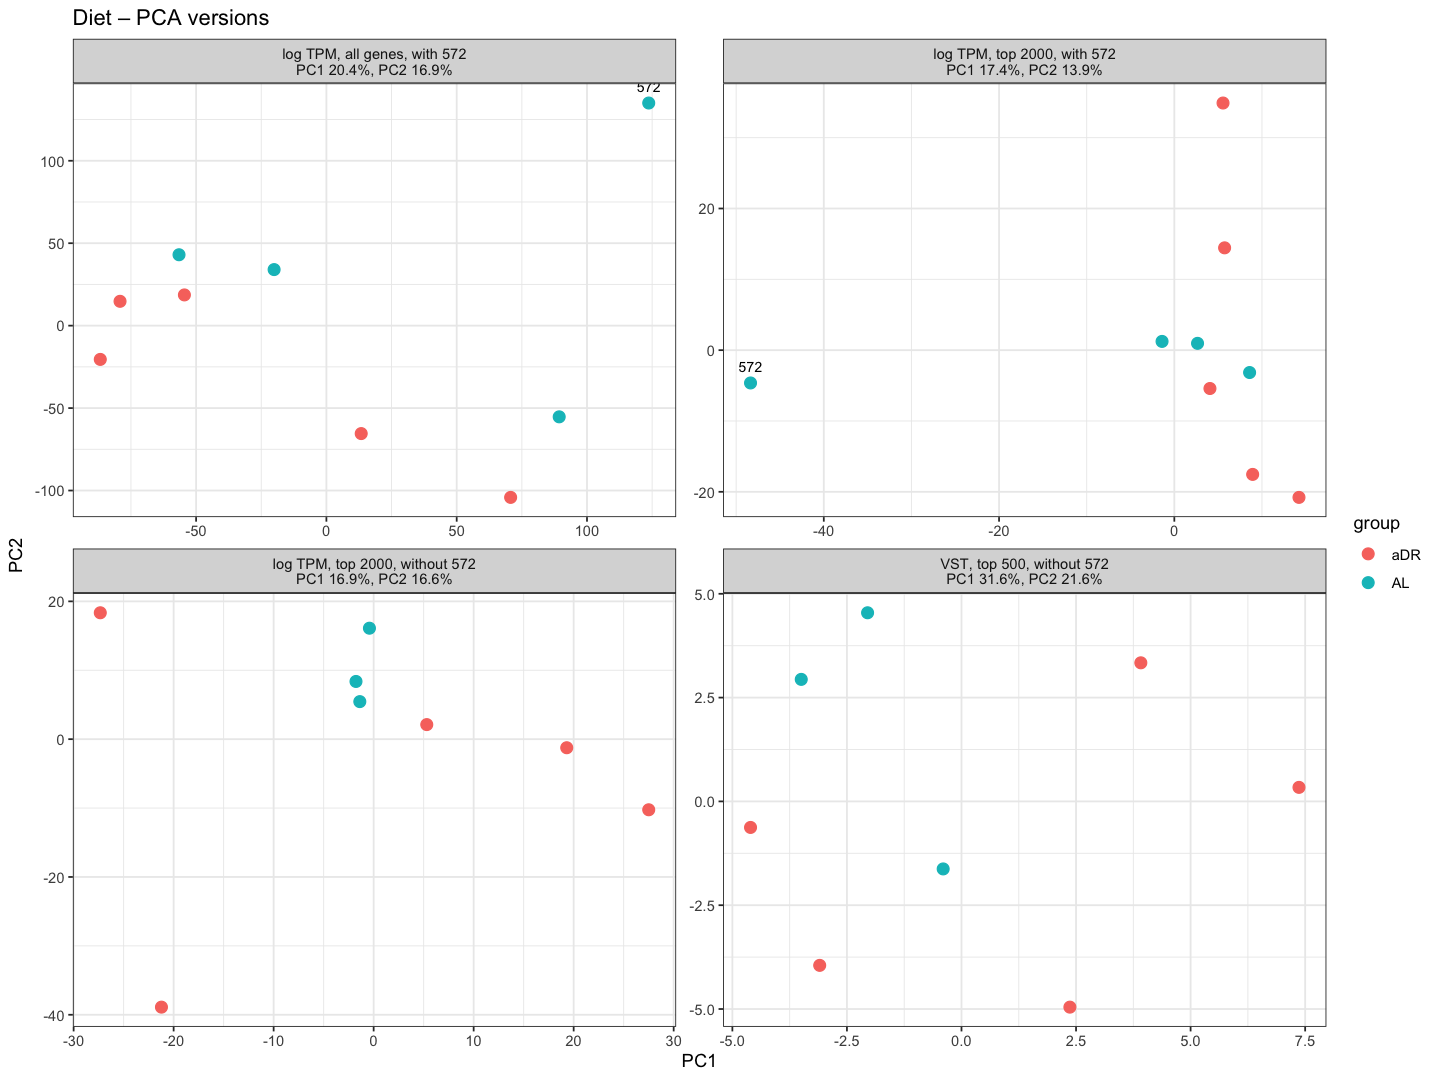

In [8]:
pca_diet <- list(
  "log TPM, all genes, with 572"  = run_pca(diet_all),
  "log TPM, top 2000, with 572"   = run_pca(diet_all,   n_top),
  "log TPM, top 2000, without 572"= run_pca(diet_clean, n_top),
  "VST, top 500, without 572"     = run_pca(diet_clean, 500, values = "vst", scale = FALSE)
)

options(repr.plot.width = 12, repr.plot.height = 9)
plot_pca_grid(pca_diet, colour = "group", title = "Diet – PCA versions")

## 1. Young Plasma Injection (PBS vs YMP)

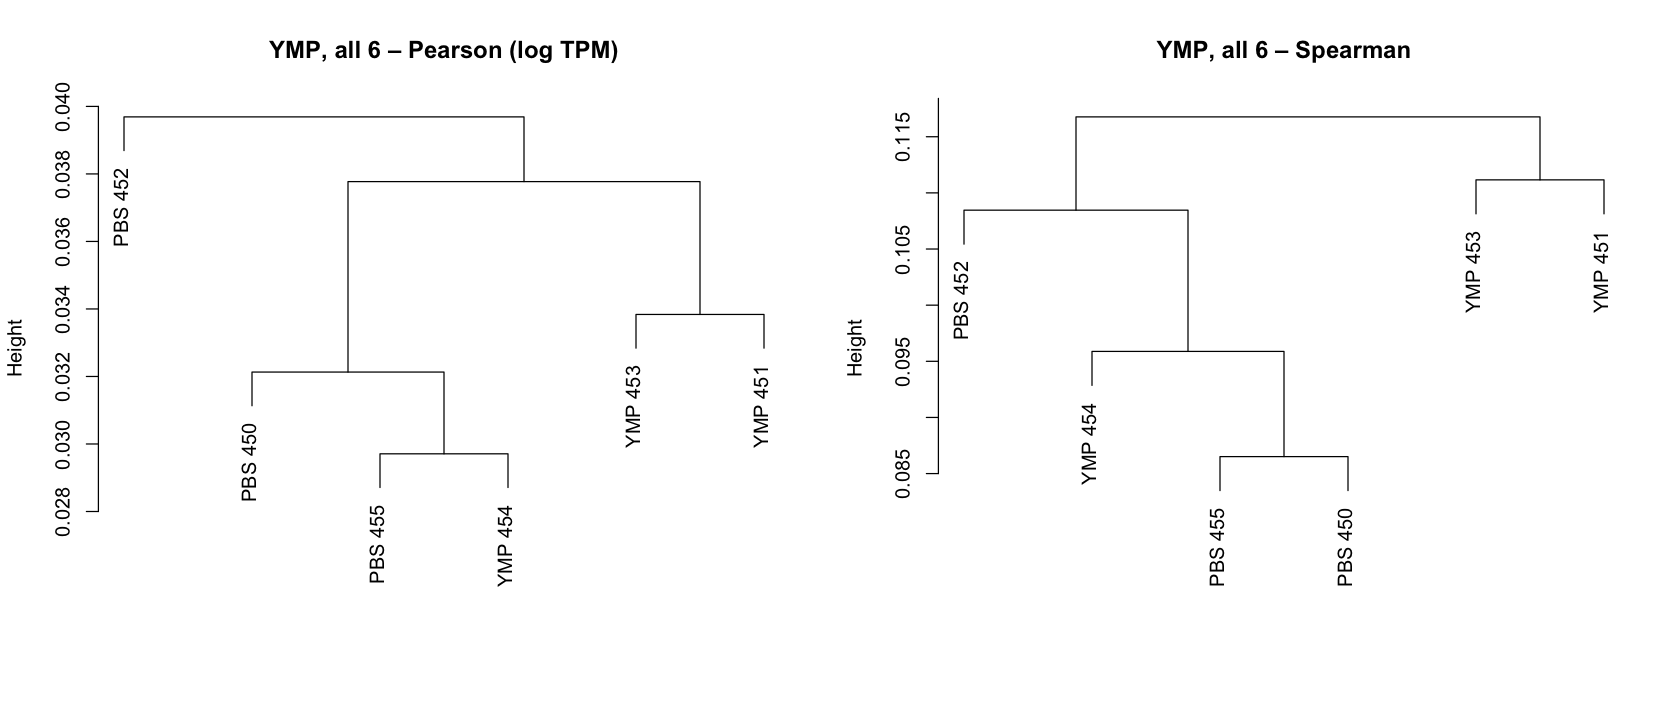

In [9]:
ymp_all <- meta$SRR[meta$cohort == "Young Plasma Injection"]

options(repr.plot.width = 14, repr.plot.height = 6)
plot_trees(ymp_all, "YMP, all 6")

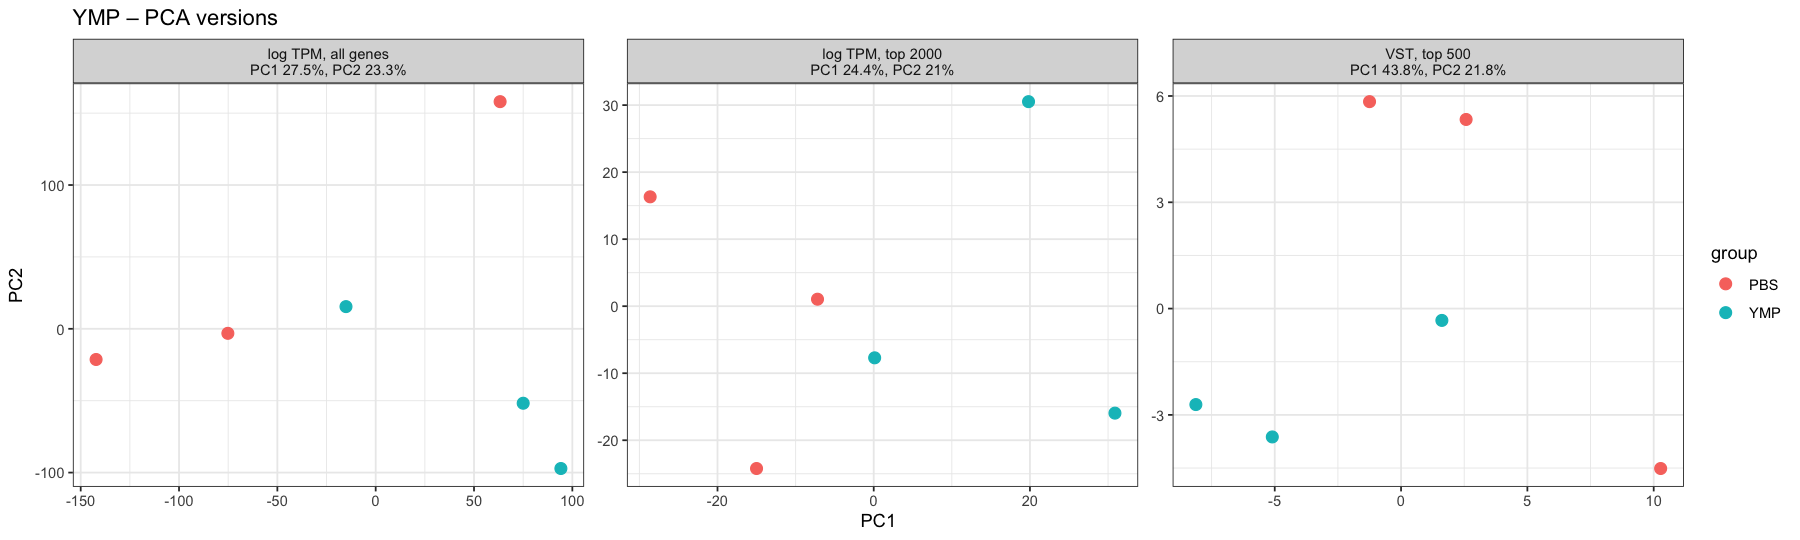

In [10]:
pca_ymp <- list(
  "log TPM, all genes" = run_pca(ymp_all),
  "log TPM, top 2000"  = run_pca(ymp_all, n_top),
  "VST, top 500"       = run_pca(ymp_all, 500, values = "vst", scale = FALSE)
)

options(repr.plot.width = 15, repr.plot.height = 4.5)
plot_pca_grid(pca_ymp, colour = "group", title = "YMP – PCA versions", ncol = 3)

## 4. How subtle are the group differences?
If the groups differed strongly, mice of the **same** group would correlate better than mice of **different** groups. Each point is one pair of samples (Spearman correlation over the expressed genes of that cohort; outliers removed).

cohort,pair,n,median_r
<chr>,<chr>,<int>,<dbl>
Aging (without 389),different group,40,0.9119
Aging (without 389),same group,15,0.9149
Diet (without 572),different group,15,0.9001
Diet (without 572),same group,13,0.8984
YMP,different group,9,0.8915
YMP,same group,6,0.8937


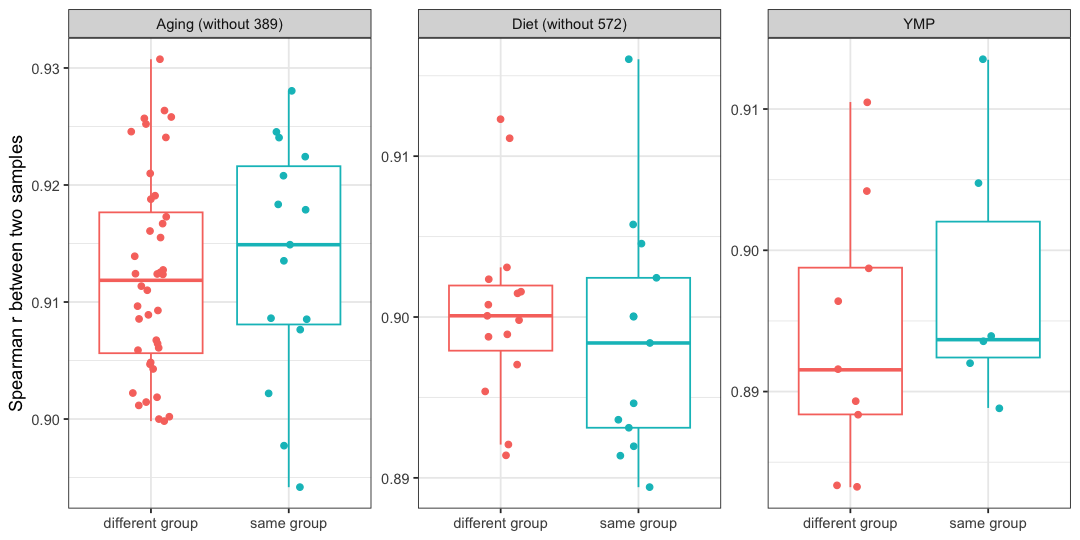

In [11]:
cohort_samples <- list(
  "Aging (without 389)"  = aging_clean,
  "Diet (without 572)"   = diet_clean,
  "YMP"                  = ymp_all
)

pairs <- bind_rows(lapply(names(cohort_samples), function(co) {
  s <- cohort_samples[[co]]
  e <- expr[, s]
  r <- cor(e[expressed_genes(e), ], method = "spearman")
  idx <- which(upper.tri(r), arr.ind = TRUE)
  g1 <- meta[s[idx[, 1]], "group"]
  g2 <- meta[s[idx[, 2]], "group"]
  data.frame(cohort = co, r = r[idx],
             pair = ifelse(g1 == g2, "same group", "different group"))
}))

pairs %>% group_by(cohort, pair) %>% summarise(n = n(), median_r = round(median(r), 4), .groups = "drop")

options(repr.plot.width = 9, repr.plot.height = 4.5)
ggplot(pairs, aes(pair, r, colour = pair)) +
  geom_boxplot(outlier.shape = NA) +
  geom_point(position = position_jitter(width = 0.15, seed = 1)) +
  facet_wrap(~ cohort, scales = "free_y") +
  labs(x = NULL, y = "Spearman r between two samples") +
  theme_bw() +
  theme(legend.position = "none")